***Problem Statement:*** Every day, the bank receives numerous loan applications from customers. Reviewing each application manually is time-consuming and may lead to inconsistent decisions. Your task is to build a machine learning model that predicts whether a loan application should be Approved or Rejected based on applicant details such as income, education, CIBIL score, loan amount, loan term, and asset values. This model will help the bank make faster, more accurate, and data-driven loan approval decisions.




***Step 1: Import Required Libraries***

In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

***Step 2: Load the Dataset***


In [6]:
df = pd.read_csv("C:/Users/Yashika/Downloads/loan_approval_dataset.csv")

In [7]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [8]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [24]:
df.columns = df.columns.str.strip()

***Step 3 Understanding the dataset***

In [9]:
df.shape

(4269, 13)

#Data set contains 4269 loan applications and 13 columns

***Step 4: Dataset Information***

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
 11  loan_status               4269 non-null   object
dtypes: int64(9), object(3)
memory usage: 400.3+ KB


In [25]:
df.describe()

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


Summary of Categorical Features

In [27]:
df.describe(include='object')

,education,self_employed,loan_status
count,4269,4269,4269
unique,2,2,2
top,Graduate,Yes,Approved
freq,2144,2150,2656


***Step 5: Data Quality Checks***

In [16]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.nunique()

loan_id                      4269
 no_of_dependents               6
 education                      2
 self_employed                  2
 income_annum                  98
 loan_amount                  378
 loan_term                     10
 cibil_score                  601
 residential_assets_value     278
 commercial_assets_value      188
 luxury_assets_value          379
 bank_asset_value             146
 loan_status                    2
dtype: int64

loan_id is only a unique identifier and doesn't provide any information that helps predict whether a loan should be approved.

In [19]:
df.drop("loan_id", axis=1, inplace=True)

In [28]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


Check Target Variable Distribution

In [29]:
df["loan_status"].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [30]:
df["loan_status"].value_counts(normalize=True) * 100

loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64


Why are we doing this?
Before training a classification model, we need to know whether the dataset is balanced or imbalanced.
If both classes have similar numbers of records → Balanced dataset  If one class dominates the other Imbalanced dataset
This influences model selection and evaluation metrics.

***Step 6: Exploratory Data Analysis (EDA)***

Exploratory Data Analysis (EDA) is the process of analyzing and visualizing the dataset to understand its underlying patterns, relationships, and distributions. It helps identify trends, detect outliers, and gain valuable insights before building a machine learning model.

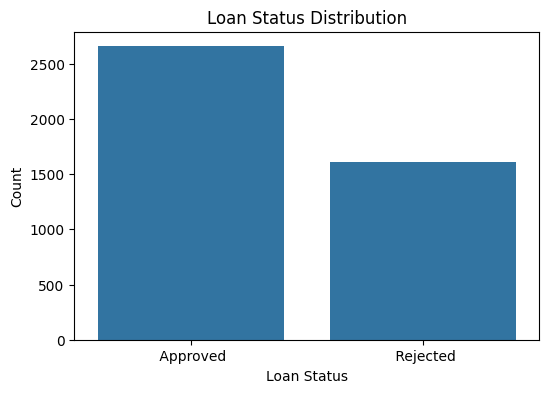

In [32]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="loan_status")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")

plt.show()

In [33]:
(df["loan_status"].value_counts(normalize=True) * 100).round(2)

loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64

The target variable is loan_status, which contains two classes: Approved and Rejected. We observe that approximately 62% of loan applications were approved, while about 38% were rejected. The dataset is reasonably balanced, making it suitable for training classification models without requiring special techniques to handle class imbalance."

Although the Approved class has more records than the Rejected class, the difference is not extreme. Therefore, the dataset is reasonably balanced and can be used for training classification models without immediately applying resampling techniques.

In [34]:
df["education"].value_counts()

education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

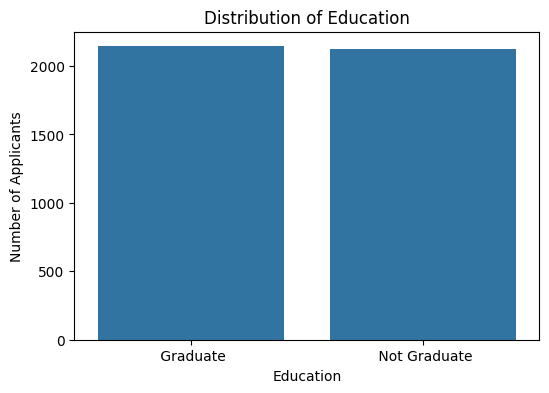

In [35]:
plt.figure(figsize=(6,4))

sns.countplot(x="education", data=df)

plt.title("Distribution of Education")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")

plt.show()

<Axes: xlabel='education', ylabel='count'>

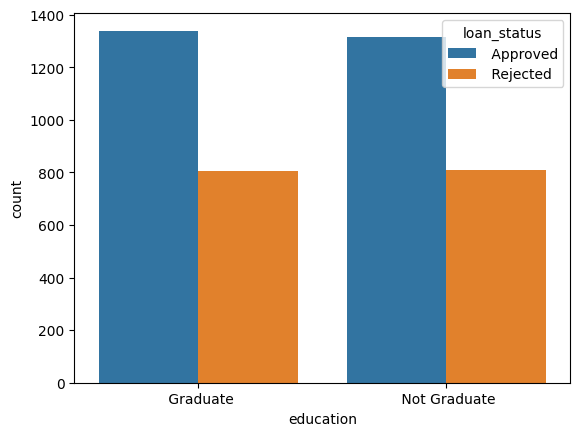

In [36]:
sns.countplot(x="education", hue="loan_status", data=df)

Based on the current visualization, both graduates and non-graduates have similar proportions of approved and rejected loans. This suggests that education alone may not be a strong predictor of loan approval. However, we cannot draw a final conclusion without further analysis and model training.

In [37]:
df["self_employed"].value_counts()

self_employed
Yes    2150
No     2119
Name: count, dtype: int64

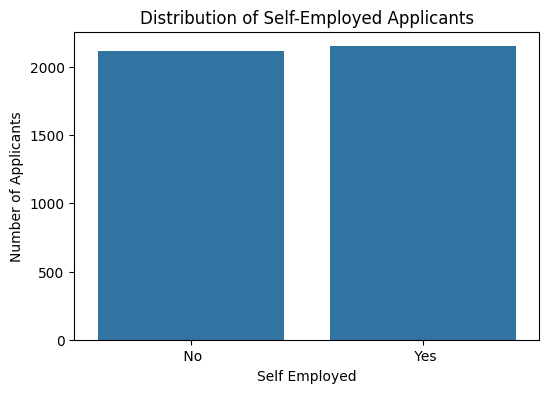

In [38]:
plt.figure(figsize=(6,4))

sns.countplot(x="self_employed", data=df)

plt.title("Distribution of Self-Employed Applicants")
plt.xlabel("Self Employed")
plt.ylabel("Number of Applicants")

plt.show()

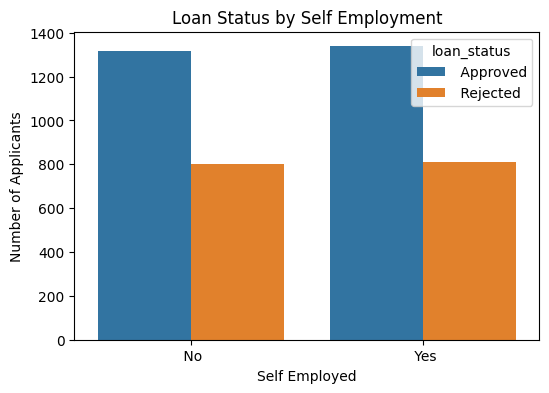

In [39]:
plt.figure(figsize=(6,4))

sns.countplot(x="self_employed", hue="loan_status", data=df)

plt.title("Loan Status by Self Employment")
plt.xlabel("Self Employed")
plt.ylabel("Number of Applicants")

plt.show()

Income Analysis


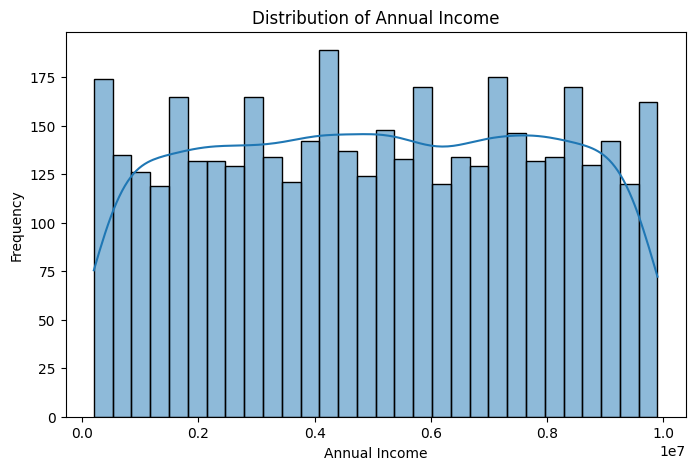

In [40]:
plt.figure(figsize=(8,5))

sns.histplot(df["income_annum"], bins=30, kde=True)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")

plt.show()

sns.histplot()

This is our first histogram.
Unlike countplot(), which is used for categorical data, a histogram is used for numerical data.
It groups numerical values into intervals (called bins) and shows how many observations fall into each interval.


The annual income appears to be fairly evenly distributed across different income ranges. The histogram does not exhibit the bell-shaped pattern of a normal distribution, and there are no obvious outliers visible from this plot.

Does annual income affect loan approval?

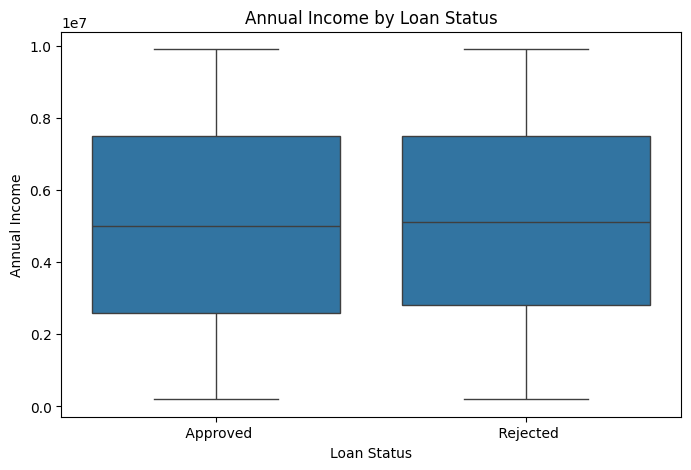

In [41]:
plt.figure(figsize=(8,5))

sns.boxplot(x="loan_status", y="income_annum", data=df)

plt.title("Annual Income by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Annual Income")

plt.show()

 ***Step 7: Correlation Analysis***

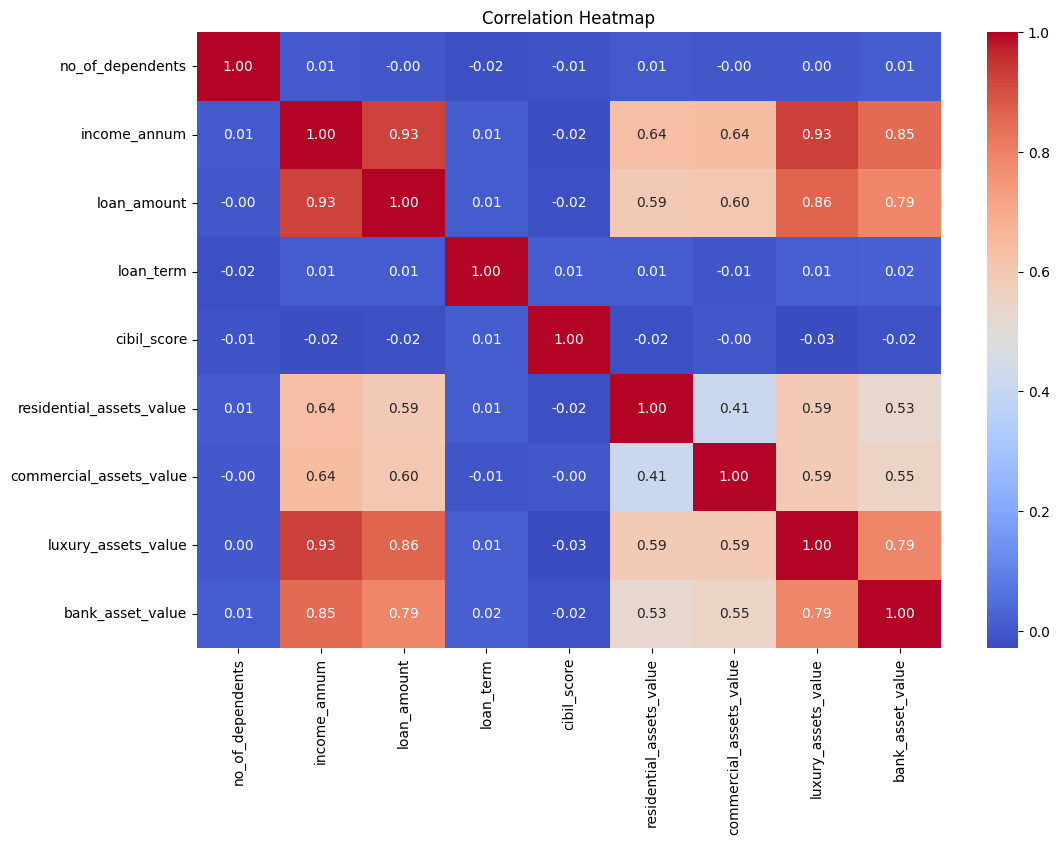

In [42]:
plt.figure(figsize=(12,8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

***Step 8 Data Preprocessing***


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
 11  loan_status               4269 non-null   object
dtypes: int64(9), object(3)
memory usage: 400.3+ KB


education         object
self_employed     object
loan_status       object

These are the columns that need to be converted into numbers. 
Why do we encode?
Machine Learning algorithms work with numbers, not text.

In [44]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder() #Create the encoder
df["education"] = label_encoder.fit_transform(df["education"]) #Encode the columns

df["self_employed"] = label_encoder.fit_transform(df["self_employed"])

df["loan_status"] = label_encoder.fit_transform(df["loan_status"])

In [45]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,0
1,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,1
2,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,1
3,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,1
4,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,1


Machine learning models cannot process text directly, so we convert categorical variables into numerical values using Label Encoding. Since our categorical features have only two unique categories each, Label Encoding is a simple and appropriate choice.
Interview Question

Q. Why did you choose Label Encoding instead of One-Hot Encoding?
We used Label Encoding because all categorical features (education, self_employed, and loan_status) are binary, meaning they each have only two unique categories. For binary features, Label Encoding is simple, efficient, and does not introduce unnecessary additional columns. One-Hot Encoding is generally preferred when a feature has more than two categories without any inherent order.

In [46]:
from sklearn.preprocessing import LabelEncoder

education_encoder = LabelEncoder()
self_employed_encoder = LabelEncoder()
loan_status_encoder = LabelEncoder()

df["education"] = education_encoder.fit_transform(df["education"])
df["self_employed"] = self_employed_encoder.fit_transform(df["self_employed"])
df["loan_status"] = loan_status_encoder.fit_transform(df["loan_status"])

***Step 9: Feature Selection and Train-Test Split***

Separate Features and Target

In [48]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

In [49]:
print(X.head())

   no_of_dependents  education  self_employed  income_annum  loan_amount  \
0                 2          0              0       9600000     29900000   
1                 0          1              1       4100000     12200000   
2                 3          0              0       9100000     29700000   
3                 3          0              0       8200000     30700000   
4                 5          1              1       9800000     24200000   

   loan_term  cibil_score  residential_assets_value  commercial_assets_value  \
0         12          778                   2400000                 17600000   
1          8          417                   2700000                  2200000   
2         20          506                   7100000                  4500000   
3          8          467                  18200000                  3300000   
4         20          382                  12400000                  8200000   

   luxury_assets_value  bank_asset_value  
0             22700

In [50]:
print(y.head())

0    0
1    1
2    1
3    1
4    1
Name: loan_status, dtype: int64


Why do we separate X and y?
In supervised learning, the model learns the relationship between the input features (X) and the target variable (y). Separating them is necessary because X is used for prediction, while y contains the correct answers used during training.

In [97]:
from sklearn.model_selection import train_test_split


In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

random_state=42
This fixes the random split.
Without it:
Every time you run the notebook, you'll get a different train-test split.
Why 42?
There's nothing mathematically special about 42. It's simply a commonly used seed value in examples. You could use 7, 10, 123, or any other integer and still get reproducible results.

In [99]:
print("Training Features:", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Labels  :", y_train.shape)
print("Testing Labels   :", y_test.shape)

Training Features: (3415, 11)
Testing Features : (854, 11)
Training Labels  : (3415,)
Testing Labels   : (854,)


***Step 10: Logistic Regression***

In [100]:
from sklearn.preprocessing import StandardScaler

In [101]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#fit_transform() learns the scaling parameters from the training data and scales it.
#transform() applies those same parameters to the test data, avoiding data leakage.

In [102]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000)
logistic_model.fit(X_train_scaled, y_train)

y_pred = logistic_model.predict(X_test_scaled)

In [103]:
print(y_pred[:10])

[1 0 1 0 0 0 0 1 0 1]


1 → Approved 0 → Rejected
because we encoded the target variable earlier.

***Step 11: Model Evaluation***

In [104]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [105]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.905152224824356


In [106]:
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 90.52%


In [107]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.93      0.92       536
           1       0.88      0.86      0.87       318

    accuracy                           0.91       854
   macro avg       0.90      0.90      0.90       854
weighted avg       0.90      0.91      0.90       854



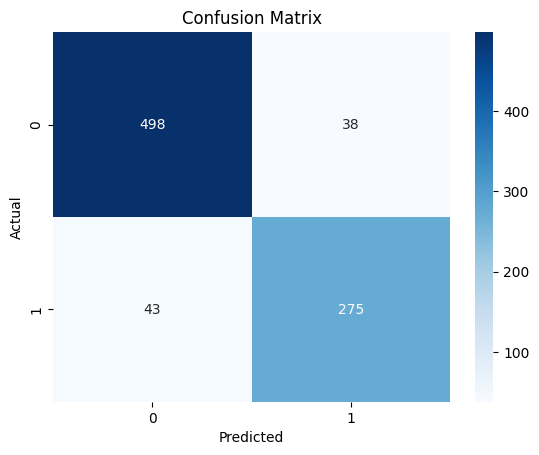

In [108]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

***Step 12: Decision Tree Classifier***

Import the Model




In [109]:
from sklearn.tree import DecisionTreeClassifier

In [110]:
decision_tree = DecisionTreeClassifier(random_state=42)

In [111]:
decision_tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

Make Predictions

In [112]:
y_pred_dt = decision_tree.predict(X_test)

Evaluate the Model

In [113]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred_dt)

print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 97.78%


In [114]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       536
           1       0.97      0.97      0.97       318

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



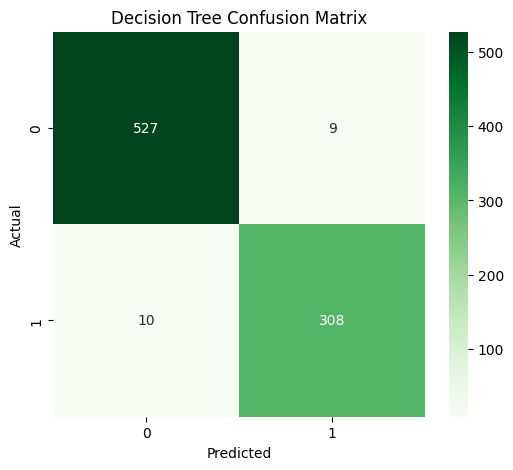

In [117]:
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Greens")

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Decision Trees perform better than Logistic Regression
Logistic Regression assumes a linear relationship between the features and the target variable. Decision Trees can model non-linear relationships and interactions between features, making them more flexible for complex datasets. 
But... here's something every data scientist should ask 🤔
98% accuracy is very high.
Whenever you see an accuracy above 95%, ask yourself:Is the model genuinely learning, or is it overfitting?"

Decision Trees are powerful, but they can memorize the training data if allowed to grow without restrictions.
Let's verify whether it's overfitting

In [118]:
train_accuracy = decision_tree.score(X_train, y_train)
test_accuracy = decision_tree.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy*100:.2f}%")
print(f"Testing Accuracy : {test_accuracy*100:.2f}%")

Training Accuracy: 100.00%
Testing Accuracy : 97.78%


The Decision Tree achieved 100% training accuracy and 97.78% testing accuracy. This indicates that the model has learned the training data very well while still generalizing effectively to unseen data. Although there is a small gap between training and testing accuracy, the model does not exhibit severe overfitting on this dataset.

***Step 13: Random Forest Classifier***

Import the Model

In [119]:
from sklearn.ensemble import RandomForestClassifier

Create the Model

In [120]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

Train the Model

In [121]:
random_forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Predict

In [122]:
y_pred_rf = random_forest.predict(X_test)

Evaluate

In [123]:
accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 97.78%


 Random Forest results are:
 Training Accuracy : 100.00%
Testing Accuracy  : 97.78%
They are exactly the same as Decision Tree.

There are two possibilities:
Possibility 1 (Most Likely)
The dataset is relatively easy to classify, so both models perform similarly.
Possibility 2
The Random Forest didn't improve because the default parameters were sufficient and the Decision Tree had already captured the patterns well.

This is perfectly fine. Not every dataset will show a dramatic improvement with Random Forest.

In [124]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       536
           1       0.98      0.96      0.97       318

    accuracy                           0.98       854
   macro avg       0.98      0.97      0.98       854
weighted avg       0.98      0.98      0.98       854



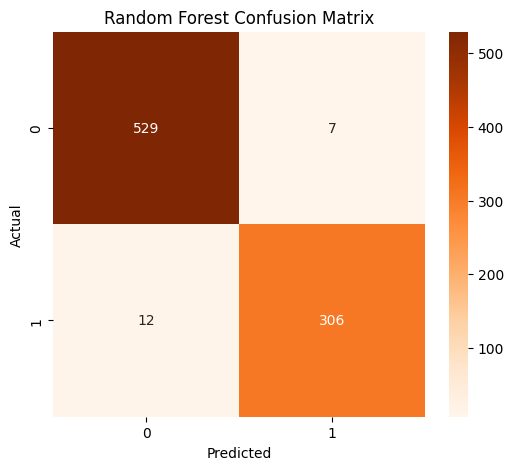

In [125]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Oranges")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [126]:
train_accuracy = random_forest.score(X_train, y_train)
test_accuracy = random_forest.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy*100:.2f}%")
print(f"Testing Accuracy : {test_accuracy*100:.2f}%")

Training Accuracy: 100.00%
Testing Accuracy : 97.78%


Random Forest is an ensemble learning algorithm that combines the predictions of multiple Decision Trees. Instead of relying on a single tree, it uses majority voting to make more accurate and robust predictions. This approach typically reduces overfitting and improves generalization.

***Final Model Comparison***

In [128]:
from sklearn.metrics import accuracy_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Scaled)",
        "Decision Tree",
        "Random Forest"
    ],
    "Test Accuracy (%)": [
        accuracy_score(
            y_test,
            logistic_model.predict(X_test_scaled)
        ) * 100,

        accuracy_score(
            y_test,
            decision_tree.predict(X_test)
        ) * 100,

        accuracy_score(
            y_test,
            random_forest.predict(X_test)
        ) * 100
    ]
})

comparison["Test Accuracy (%)"] = comparison["Test Accuracy (%)"].round(2)

display(comparison)

,Model,Test Accuracy (%)
0,Logistic Regression (Scaled),90.52
1,Decision Tree,97.78
2,Random Forest,97.78


This is one of the best parts of Random Forest because it tells us which features influenced the predictions the most.

In [83]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
6,cibil_score,0.809939
5,loan_term,0.064499
4,loan_amount,0.028938
7,residential_assets_value,0.018168
3,income_annum,0.018060
9,luxury_assets_value,0.017745
10,bank_asset_value,0.015261
8,commercial_assets_value,0.014440
0,no_of_dependents,0.008385
2,self_employed,0.002473


C:\Users\Yashika\AppData\Local\Temp\ipykernel_21484\1954146019.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


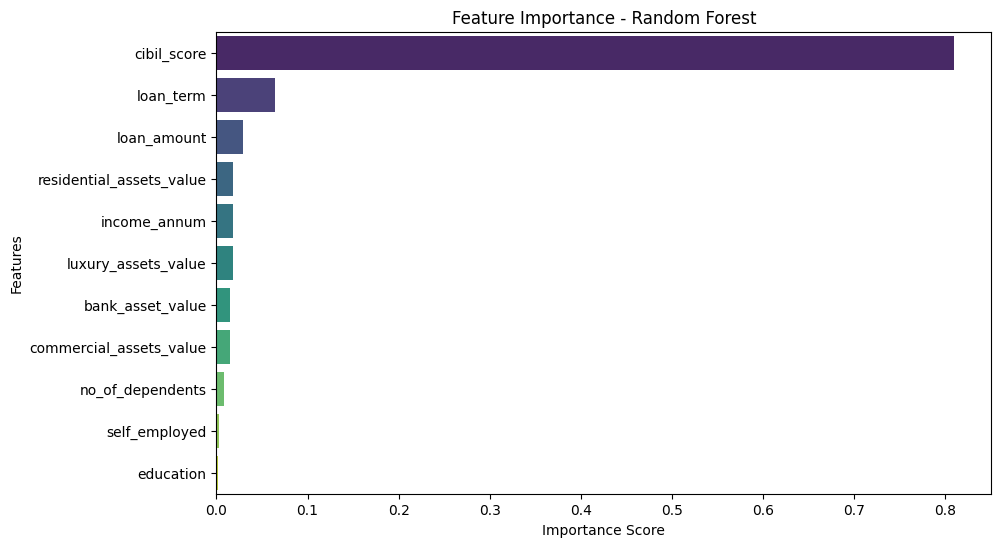

In [84]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

Feature importance helps us understand which features contributed the most to the model's predictions. Features with higher importance scores have a greater influence on whether a loan is approved or rejected.